# Uncertainty and calibration, introduction

Skoltech · Seminar

## 1. A toy 1D binary classification problem

### 1.1. Model and data

We begin with a binary classification problem on a one-dimensional input. For each observation we see a real number $x\in\mathbb R$ and a label $y\in\{0,1\}$. The labels are generated from a Bernoulli model

$$
Y\mid x,c \sim \operatorname{Bernoulli}(p_c(x)),
$$

where $c$ is an unknown parameter controlling the location of one transition region. The class-probability function is written explicitly as

$$
\sigma(t)=\frac{1}{1+e^{-t}},
$$
$$
a(x)=\sigma\bigl(\kappa(x+3)\bigr),\qquad
b_c(x)=\sigma\bigl(-\kappa(x-c)\bigr),\qquad
r(x)=\sigma\bigl(\kappa(x-2.55)\bigr),
$$
$$
p_c(x)=1-\bigl(1-a(x)b_c(x)\bigr)\bigl(1-r(x)\bigr).
$$

The constant $\kappa=14$ controls the steepness of the logistic transitions. The factor $a(x)$ turns the left positive region on near $x=-3$. The factor $b_c(x)$ turns it off again near $x=c$. The factor $r(x)$ turns the right positive region on near $x=2.55$. The product $a(x)b_c(x)$ therefore describes a positive region on the left, and the final formula combines that region with the right positive tail.

The unknown quantity is the transition location $c$. We use a Gaussian prior,

$$
C\sim \mathcal N(m_0,s_0^2),\qquad m_0=-0.45,\quad s_0=0.35,
$$

and approximate the resulting posterior density on a dense grid $c_1,\ldots,c_M$ with $M=301$ points between $-1.2$ and $0.35$. If $w_j^{(0)}$ denotes the normalized prior weight at $c_j$, then after observing data $\mathcal D=\{(x_i,y_i)\}_{i=1}^N$ the posterior weights are

$$
w_j\propto w_j^{(0)}\prod_{i=1}^{N} p_{c_j}(x_i)^{y_i}\bigl(1-p_{c_j}(x_i)\bigr)^{1-y_i},
\qquad \sum_{j=1}^{M} w_j = 1.
$$

The training inputs are placed in two intervals, $[-5,-1.8]$ and $[1.1,5]$. The data therefore show the left rise and the right rise, but they do not directly observe the uncertain transition near $x=c$.


The code uses NumPy, SciPy, pandas, Matplotlib and scikit-learn, with threadpoolctl for CPU thread control. No data files or downloads are required. Run the cells in order. Complete each function marked `TODO`; the surrounding experiment and checks are provided. An unfinished exercise does not prevent running the next section.

In [2]:
from __future__ import annotations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import cho_factor, cho_solve
from scipy.optimize import minimize_scalar
from scipy.special import expit, logsumexp, xlogy
from scipy.stats import norm
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

%matplotlib inline
plt.rcParams.update({"figure.figsize": (8.0, 4.5), "figure.dpi": 140,
                     "font.size": 11, "axes.titlesize": 12})


def binary_entropy(p):
    """Bernoulli entropy in nats; 0 log 0 is evaluated as 0."""
    p = np.asarray(p, dtype=float)
    if np.any(~np.isfinite(p)) or np.any((p < 0) | (p > 1)):
        raise ValueError("Probabilities must be finite and lie in [0, 1].")
    return -xlogy(p, p) - xlogy(1 - p, 1 - p)


np.testing.assert_allclose(binary_entropy([0, 0.5, 1]), [0, np.log(2), 0])

### 1.2. Predictive distribution and uncertainty decomposition

For a future label $Y_\star$ at an input $x_\star$, the posterior predictive probability is

$$
P(Y_\star=1\mid x_\star,\mathcal D)=\int p_c(x_\star)\,p(c\mid\mathcal D)\,dc.
$$

On the grid this integral is approximated by the finite weighted sum

$$
\bar p(x_\star)=\sum_{j=1}^{M} w_j p_{c_j}(x_\star).
$$

The full predictive distribution is Bernoulli$(\bar p(x_\star))$. To separate two kinds of uncertainty, define the Bernoulli entropy

$$
h(p)=-p\log p-(1-p)\log(1-p),\qquad 0\log 0 := 0.
$$

At a fixed input $x$, the predictive entropy is $h(\bar p(x))$. The posterior-averaged conditional entropy is

$$
\mathbb E_{C\mid\mathcal D}\bigl[h(p_C(x))\bigr]
\approx \sum_{j=1}^{M} w_j h\bigl(p_{c_j}(x)\bigr).
$$

The decomposition is

$$
h(\bar p(x)) = \mathbb E_{C\mid\mathcal D}\bigl[h(p_C(x))\bigr] + I(Y_\star;C\mid x,\mathcal D).
$$

The first term measures uncertainty that remains even if $c$ were known. In this example it is large near the smooth class boundaries. The mutual information term measures predictive disagreement across plausible values of $c$, so it is large near the unobserved transition around $x=c$.


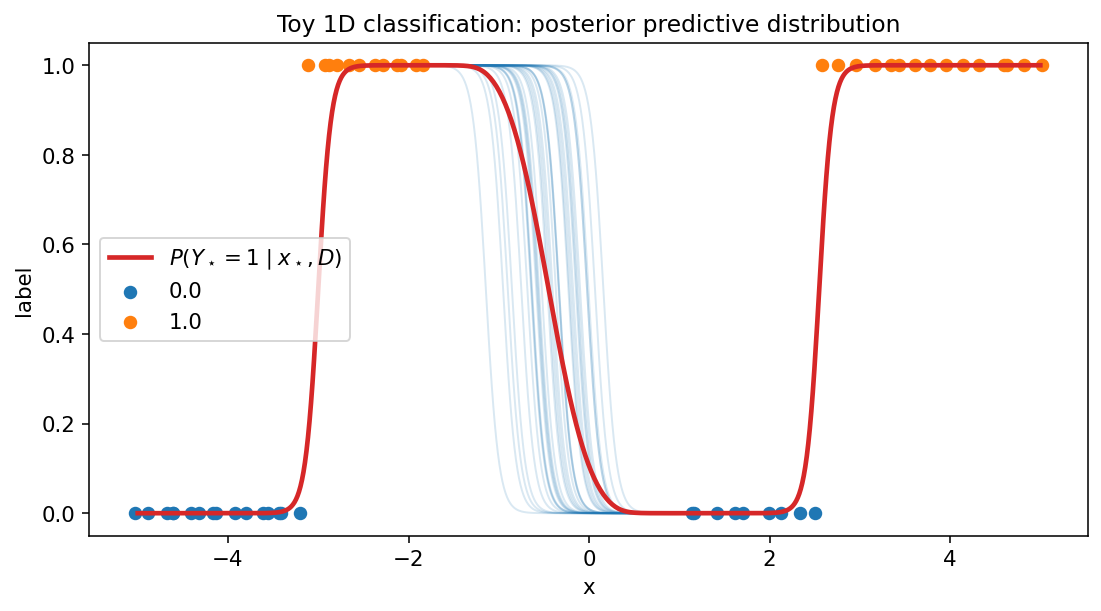

 posterior mean of c  posterior sd of c  number of training points
             -0.4461             0.3217                         52


In [3]:
TOY_STEEPNESS = 14.0
TOY_LEFT_EDGE = -3.0
TOY_RIGHT_EDGE = 2.55
TOY_TRUE_C = -0.55


def toy_probability(x, c, kappa=TOY_STEEPNESS,
                    left_edge=TOY_LEFT_EDGE, right_edge=TOY_RIGHT_EDGE):
    """Class-1 probability p_c(x) for the toy 1D classifier."""
    x = np.asarray(x, dtype=float)[..., None]
    c = np.asarray(c, dtype=float)[None, ...]
    a = expit(kappa * (x - left_edge))
    b = expit(-kappa * (x - c))
    r = expit(kappa * (x - right_edge))
    left_region = a * b
    probability = 1 - (1 - left_region) * (1 - r)
    return np.squeeze(probability)


def normalize_weights(log_weights):
    """Convert unnormalized log-weights to normalized weights."""
    log_weights = np.asarray(log_weights, dtype=float)
    return np.exp(log_weights - logsumexp(log_weights))


c_grid = np.linspace(-1.2, 0.35, 301)
prior_weights = norm.pdf(c_grid, loc=-0.45, scale=0.35)
prior_weights /= prior_weights.sum()


def toy_log_likelihood(candidates, x, y):
    """Log-likelihood on the candidate grid of c values."""
    probabilities = np.clip(toy_probability(x, candidates), 1e-10, 1 - 1e-10)
    return (y[:, None] * np.log(probabilities)
            + (1 - y)[:, None] * np.log(1 - probabilities)).sum(axis=0)


toy_rng = np.random.default_rng(4)
x_toy = np.r_[np.linspace(-5.0, -1.8, 28), np.linspace(1.1, 5.0, 24)]
x_toy = x_toy + toy_rng.normal(0, 0.05, len(x_toy))
y_toy = toy_rng.binomial(1, toy_probability(x_toy, TOY_TRUE_C))

posterior_weights = normalize_weights(np.log(prior_weights + 1e-300)
                                      + toy_log_likelihood(c_grid, x_toy, y_toy))
posterior_mean_c = np.dot(posterior_weights, c_grid)
posterior_sd_c = np.sqrt(np.dot(posterior_weights, (c_grid - posterior_mean_c)**2))

x_toy_grid = np.linspace(-5, 5, 600)
toy_model_probabilities = np.asarray(toy_probability(x_toy_grid, c_grid))
toy_predictive_mean = toy_model_probabilities @ posterior_weights

sampled_c = toy_rng.choice(c_grid, size=35, replace=True, p=posterior_weights)
toy_sample_curves = np.asarray(toy_probability(x_toy_grid, sampled_c))

fig, ax = plt.subplots()
for j in range(toy_sample_curves.shape[1]):
    ax.plot(x_toy_grid, toy_sample_curves[:, j], color="C0", alpha=0.17, lw=1)
ax.plot(x_toy_grid, toy_predictive_mean, color="C3", lw=2.4,
        label=r"$P(Y_\star=1\mid x_\star, D)$")
ax.scatter(x_toy[y_toy == 0], np.zeros((y_toy == 0).sum()), s=35, label="0.0")
ax.scatter(x_toy[y_toy == 1], np.ones((y_toy == 1).sum()), s=35, label="1.0")
ax.set(xlabel="x", ylabel="label", ylim=(-0.05, 1.05),
       title="Toy 1D classification: posterior predictive distribution")
ax.legend(loc="center left")
fig.tight_layout()
plt.show()


print(pd.DataFrame([
    {"posterior mean of c": posterior_mean_c,
     "posterior sd of c": posterior_sd_c,
     "number of training points": len(x_toy)}
]).round(4).to_string(index=False))

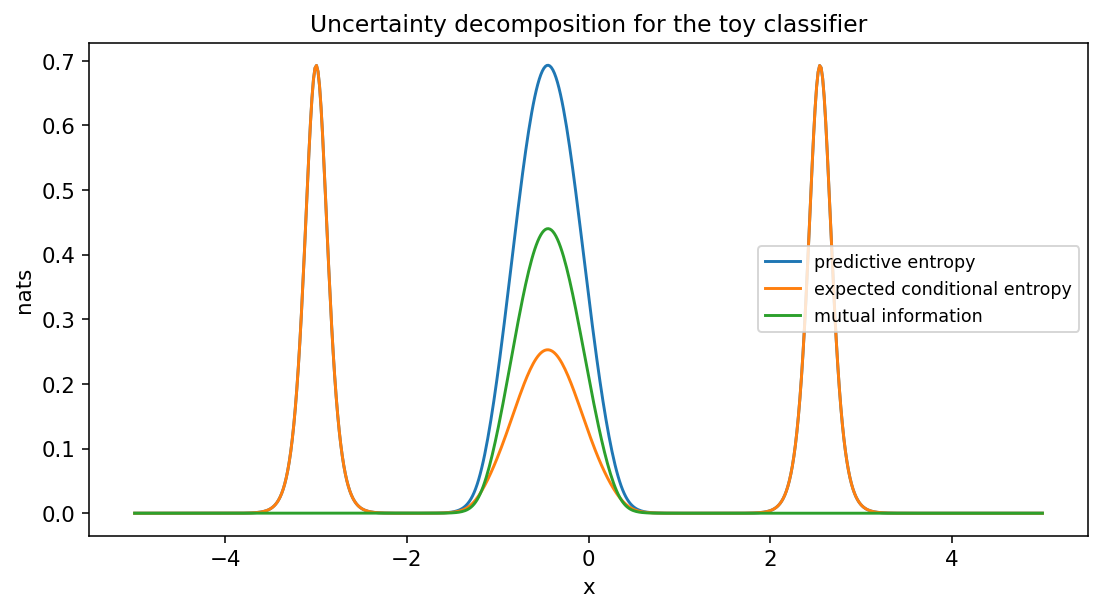

    x  P(Y*=1 | x, D)  E[h(p_C(x)) | D]  h(P(Y*=1 | x, D))  MI(Y*; C | x, D)
-3.00          0.5000            0.6931             0.6931            0.0000
-0.45          0.5025            0.2529             0.6931            0.4403
 2.55          0.5000            0.6931             0.6931            0.0000


In [3]:
toy_expected_entropy = binary_entropy(toy_model_probabilities) @ posterior_weights
toy_predictive_entropy = binary_entropy(toy_predictive_mean)
toy_epistemic = toy_predictive_entropy - toy_expected_entropy


def toy_decomposition_at(weights, x_query):
    """Predictive probability and entropy decomposition at one x value."""
    weights = np.asarray(weights, dtype=float)
    point_probabilities = np.clip(np.ravel(toy_probability([x_query], c_grid)), 1e-12, 1 - 1e-12)
    predictive = np.dot(weights, point_probabilities)
    within = np.dot(weights, binary_entropy(point_probabilities))
    total = binary_entropy(predictive)
    epistemic = total - within
    return predictive, within, total, epistemic


fig, ax = plt.subplots()
ax.plot(x_toy_grid, toy_predictive_entropy, label="predictive entropy")
ax.plot(x_toy_grid, toy_expected_entropy, label="expected conditional entropy")
ax.plot(x_toy_grid, toy_epistemic, label="mutual information")
ax.set(xlabel="x", ylabel="nats",
       title="Uncertainty decomposition for the toy classifier")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

summary_points = np.array([-3.0, -0.45, 2.55])
rows = []
for x_query in summary_points:
    predictive, within, total, epistemic = toy_decomposition_at(posterior_weights, x_query)
    rows.append({"x": x_query,
                 "P(Y*=1 | x, D)": predictive,
                 "E[h(p_C(x)) | D]": within,
                 "h(P(Y*=1 | x, D))": total,
                 "MI(Y*; C | x, D)": epistemic})
print(pd.DataFrame(rows).round(4).to_string(index=False))

### Exercise 1. Which observation locations reduce uncertainty about the model? (10 minutes)

Complete `update_c_posterior`. It receives the current grid approximation to $p(c\mid\mathcal D)$, one new input `x_new`, and its binary label `label`. Return the updated posterior weights after one Bayes step.

The supplied experiment compares three measurement locations. At $x=-2.5$ and $x=3.2$ the label is already almost determined by all plausible values of $c$, so little is learned about the uncertain transition. At $x=-0.45$ the posterior predictive distribution is sensitive to $c$, so the observation should be more informative.


In [4]:
def update_c_posterior(weights, x_new, label):
    """Update the discretized posterior p(c | D) after one binary observation."""
    weights = np.asarray(weights, dtype=float)
    if label not in (0, 1) or weights.shape != c_grid.shape:
        raise ValueError("Use a binary label and a one-dimensional weight vector on c_grid.")
    p_one = np.clip(np.ravel(toy_probability([x_new], c_grid)), 1e-12, 1 - 1e-12)
    # TODO: evaluate the likelihood of the observed label under each c_j.
    # TODO: multiply the current weights by that likelihood.
    # TODO: normalize the resulting weights so that they sum to one.
    return None


# Experiment and checks
probe_update = update_c_posterior(posterior_weights, -0.45, 1)
if probe_update is None:
    print("Complete update_c_posterior, then rerun this cell.")
else:
    manual = posterior_weights * np.ravel(toy_probability([-0.45], c_grid))
    manual /= manual.sum()
    np.testing.assert_allclose(probe_update, manual)
    fig, ax = plt.subplots()
    for x_query in (-2.5, -0.45, 3.2):
        experiment_rng = np.random.default_rng(104)
        labels = experiment_rng.binomial(1, toy_probability(np.full(12, x_query), TOY_TRUE_C))
        weights = posterior_weights.copy()
        trace = [toy_decomposition_at(weights, -0.45)[3]]
        for label in labels:
            weights = update_c_posterior(weights, x_query, int(label))
            trace.append(toy_decomposition_at(weights, -0.45)[3])
        posterior_mean = np.dot(weights, c_grid)
        posterior_sd = np.sqrt(np.dot(weights, (c_grid - posterior_mean)**2))
        print(f"Observe at x={x_query:>4}: final posterior sd(c) = {posterior_sd:.4f}")
        ax.plot(np.arange(13), trace, marker="o", label=f"observe at x={x_query:g}")
    ax.set(xlabel="Number of additional labels", ylabel="Mutual information at x=-0.45",
           title="Measurements near the uncertain transition are the most informative")
    ax.legend(fontsize=9)
    fig.tight_layout()
    plt.show()

Complete update_c_posterior, then rerun this cell.


### Questions

1. Why can predictive entropy be high near $x=-3$ or $x=2.55$ even when mutual information is small?
2. Why is the mutual-information term concentrated near the uncertain transition around $x=c$?

### Bonus 1. Expected information gain

For a candidate measurement location $x$, the expected information gain about $C$ is

$$
I(Y;C\mid x,\mathcal D)=H(C\mid\mathcal D)-\mathbb E_{Y\mid x,\mathcal D}\bigl[H(C\mid x,Y,\mathcal D)\bigr].
$$

This quantity is equal to the mutual information between the next label and the uncertain parameter. It identifies where one additional observation is expected to be most useful.


In [5]:
def discrete_entropy(weights):
    """Entropy of a discrete distribution with natural logarithms."""
    weights = np.asarray(weights, dtype=float)
    positive = weights > 0
    return -np.sum(weights[positive] * np.log(weights[positive]))


def expected_posterior_entropy(weights, x_new):
    """Expected entropy of the c-posterior after one label at x_new."""
    weights = np.asarray(weights, dtype=float)
    p_one = np.clip(np.ravel(toy_probability([x_new], c_grid)), 1e-12, 1 - 1e-12)
    # TODO: compute the predictive probability of label 1 at x_new.
    # TODO: update the weights for labels 0 and 1.
    # TODO: average the two posterior entropies with the predictive probabilities.
    return None


# Experiment and checks
if update_c_posterior(posterior_weights, -0.45, 1) is None:
    print("Complete Exercise 1 before Bonus 1.")
elif expected_posterior_entropy(posterior_weights, -0.45) is None:
    print("Complete expected_posterior_entropy, then rerun this cell.")
else:
    info_gain = np.array([
        discrete_entropy(posterior_weights) - expected_posterior_entropy(posterior_weights, x)
        for x in x_toy_grid
    ])
    fig, ax = plt.subplots()
    ax.plot(x_toy_grid, info_gain)
    ax.set(xlabel="x", ylabel="Expected information gain",
           title="Where one more label would be most informative")
    fig.tight_layout()
    plt.show()
    print(f"Maximum expected information gain near x = {x_toy_grid[np.argmax(info_gain)]:.3f}")

Complete Exercise 1 before Bonus 1.


## 2. Regression with a gap in the observations

### 2.1. Data and basis-function model

We now observe a scalar input $x\in\mathbb R$ and a real-valued response. Generate 36 observations, with 18 inputs uniform on $[-4,-1]$ and 18 uniform on $[1,4]$:

$$
y_i=f_0(x_i)+\varepsilon_i,\qquad
f_0(x)=0.7\sin(1.4x)+0.15x,\qquad
\varepsilon_i\overset{\mathrm{ind}}\sim\mathcal N(0,\sigma^2),\quad \sigma=0.25.
$$

Here $f_0$ is the fixed data-generating function, $\varepsilon_i$ is independent observation noise, and $\sigma$ is its standard deviation. The learner is given the noisy observations, not the formula for $f_0$. The gap $(-1,1)$ contains no training inputs.

For inference, use a model linear in weights but nonlinear in the input:

$$
f_w(x)=\phi(x)^\top w,\qquad
Y\mid x,w\sim\mathcal N(f_w(x),\sigma^2),\qquad
w\sim\mathcal N(0,\alpha^{-1}I_{26}),\quad \alpha=2.
$$

The vector $w\in\mathbb R^{26}$ contains an intercept weight and 25 basis weights. The matrix $I_{26}$ is the $26\times26$ identity; $\alpha$ is the prior precision, so each weight has prior variance $1/\alpha$. The noise variance is known and fixed in the main experiment. We also fix the basis and prior precision rather than infer them.

The feature map is specified explicitly:

$$
\phi(x)=(\phi_0(x),\phi_1(x),\ldots,\phi_{25}(x))^\top,\qquad \phi_0(x)=1,
$$
$$
\phi_j(x)=\exp\!\left[-\frac{(x-c_j)^2}{2\ell^2}\right],\qquad
c_j=-5+\frac{10(j-1)}{24},\quad j=1,\ldots,25,\qquad \ell=0.65.
$$

Thus $c_j$ are equally spaced centres from $-5$ to $5$, and $\ell$ controls the width of each Gaussian radial basis function. The intercept is included in $\phi$ and receives the same prior variance as the other weights.

Equivalently, this prior on functions has covariance kernel

$$
k(x,x')=\operatorname{Cov}(f_w(x),f_w(x'))
=\alpha^{-1}\phi(x)^\top\phi(x')
=\alpha^{-1}\left[1+\sum_{j=1}^{25}\phi_j(x)\phi_j(x')\right].
$$

Here $x'$ is a second input and covariance is taken over the prior on $w$. This finite-rank kernel is not the usual squared-exponential kernel, despite the Gaussian-shaped basis functions [3]. The synthetic $f_0$ need not belong exactly to this finite feature space, so exact inference within the model does not establish that the model is correctly specified.

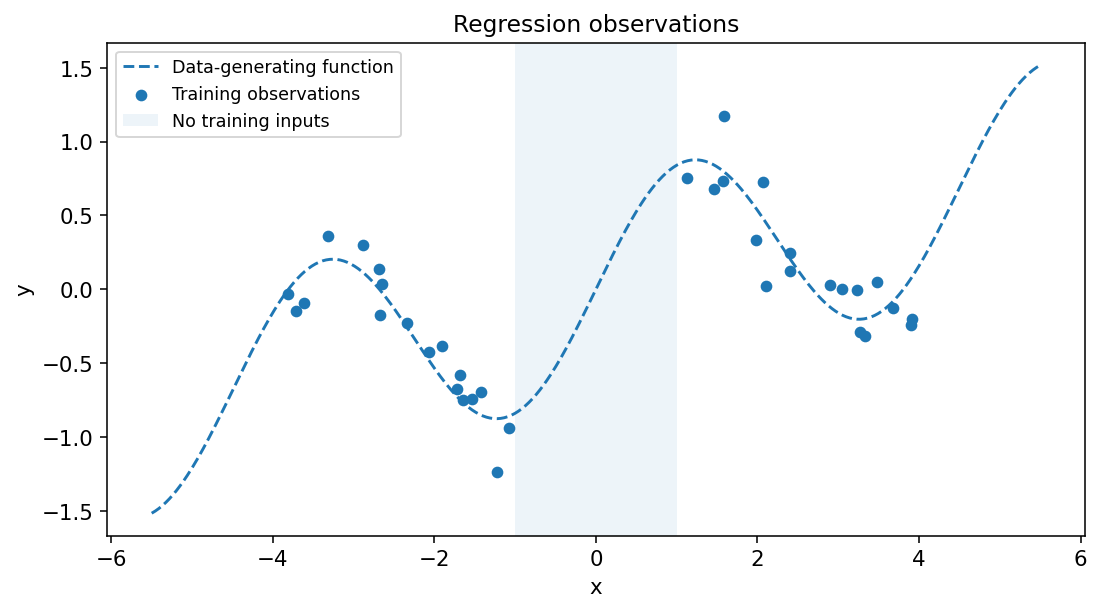

In [6]:
NOISE_STD = 0.25
PRIOR_PRECISION = 2.0
RBF_CENTERS = np.linspace(-5.0, 5.0, 25)
RBF_WIDTH = 0.65


def true_function(x):
    return 0.7 * np.sin(1.4 * np.asarray(x)) + 0.15 * np.asarray(x)


def rbf_features(x, centers=RBF_CENTERS, width=RBF_WIDTH):
    """Return [1, exp(-(x-c_j)^2/(2*width^2))], one row per input."""
    if width <= 0:
        raise ValueError("Basis width must be positive.")
    x = np.asarray(x, dtype=float).reshape(-1, 1)
    centers = np.asarray(centers, dtype=float).reshape(1, -1)
    return np.column_stack([np.ones(len(x)), np.exp(-0.5 * ((x - centers) / width) ** 2)])


reg_rng = np.random.default_rng(42)
x_reg = np.sort(np.r_[reg_rng.uniform(-4, -1, 18), reg_rng.uniform(1, 4, 18)])
y_reg = true_function(x_reg) + reg_rng.normal(0, NOISE_STD, len(x_reg))
Phi_train = rbf_features(x_reg)
x_reg_grid = np.linspace(-5.5, 5.5, 500)
Phi_grid = rbf_features(x_reg_grid)

fig, ax = plt.subplots()
ax.plot(x_reg_grid, true_function(x_reg_grid), "--", label="Data-generating function")
ax.scatter(x_reg, y_reg, s=25, label="Training observations")
ax.axvspan(-1, 1, alpha=0.08, label="No training inputs")
ax.set(xlabel="x", ylabel="y", title="Regression observations")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

### 2.2. Posterior over weights

Let $\Phi\in\mathbb R^{N\times26}$ be the design matrix with row $i$ equal to $\phi(x_i)^\top$, and let $y=(y_1,\ldots,y_N)^\top\in\mathbb R^N$ be the response vector. Here $N=36$. Conditioning on the training inputs, the likelihood is $\mathcal N(y\mid\Phi w,\sigma^2I_N)$.

Multiply likelihood and prior and keep the terms that depend on $w$:

$$
\log p(w\mid\mathcal D)
=\mathrm{const}-\frac{1}{2\sigma^2}(y-\Phi w)^\top(y-\Phi w)
-\frac{\alpha}{2}w^\top w.
$$

Expanding the quadratic gives a precision matrix and a linear coefficient:

$$
A_N=\alpha I_{26}+\sigma^{-2}\Phi^\top\Phi,\qquad
b_N=\sigma^{-2}\Phi^\top y.
$$

The matrix $A_N$ is $26\times26$ and positive definite because $\alpha>0$; $b_N$ has length 26. Completing the square,

$$
-\tfrac12 w^\top A_N w+w^\top b_N
=-\tfrac12(w-m_N)^\top A_N(w-m_N)+\mathrm{const},
$$
$$
p(w\mid\mathcal D)=\mathcal N(w\mid m_N,S_N),\qquad
S_N=A_N^{-1},\qquad m_N=S_Nb_N.
$$

Here $m_N$ is the posterior mean vector and $S_N$ is the posterior covariance matrix. The inverse is useful notation, but the implementation solves linear systems using a Cholesky factorization [3]. Notice that, with the basis, $\alpha$ and $\sigma$ fixed, $S_N$ depends on the training inputs but not on their observed responses.

In [7]:
def fit_blr(Phi, y, alpha=PRIOR_PRECISION, sigma=NOISE_STD):
    """Gaussian posterior for fixed features, prior precision and noise."""
    Phi, y = np.asarray(Phi, dtype=float), np.asarray(y, dtype=float)
    if Phi.ndim != 2 or y.shape != (len(Phi),) or alpha <= 0 or sigma <= 0:
        raise ValueError("Check design/target shapes and positive alpha, sigma.")
    dimension = Phi.shape[1]
    precision = alpha * np.eye(dimension) + Phi.T @ Phi / sigma**2
    rhs = Phi.T @ y / sigma**2
    factor = cho_factor(precision, lower=True)
    mean = cho_solve(factor, rhs)
    covariance = cho_solve(factor, np.eye(dimension))
    covariance = 0.5 * (covariance + covariance.T)
    return mean, covariance


weight_mean, weight_covariance = fit_blr(Phi_train, y_reg)
np.testing.assert_allclose(weight_covariance, weight_covariance.T, atol=1e-12)
print("Posterior mean shape:", weight_mean.shape)
print("Posterior covariance shape:", weight_covariance.shape)

Posterior mean shape: (26,)
Posterior covariance shape: (26, 26)


### 2.3. Latent function and future observation

At a new input $x_\star$, write $\phi_\star=\phi(x_\star)\in\mathbb R^{26}$. The latent value $F_\star=f_w(x_\star)=\phi_\star^\top w$ is a linear transformation of Gaussian weights. Therefore

$$
F_\star\mid x_\star,\mathcal D
\sim\mathcal N(\mu_\star,v_{\mathrm{epi},\star}),\qquad
\mu_\star=\phi_\star^\top m_N,\quad
v_{\mathrm{epi},\star}=\phi_\star^\top S_N\phi_\star.
$$

A future measurement is $Y_\star=F_\star+\varepsilon_\star$, where $\varepsilon_\star\sim\mathcal N(0,\sigma^2)$ is independent of the weights and training noise. Integrating the conditional observation model over the posterior yields

$$
p(y_\star\mid x_\star,\mathcal D)
=\int\mathcal N(y_\star\mid\phi_\star^\top w,\sigma^2)
      \mathcal N(w\mid m_N,S_N)\,dw
=\mathcal N(y_\star\mid\mu_\star,v_{\mathrm{total},\star}),
$$
$$
v_{\mathrm{total},\star}
=\underbrace{\sigma^2}_{v_{\mathrm{alea},\star}}
+\underbrace{\phi_\star^\top S_N\phi_\star}_{v_{\mathrm{epi},\star}}.
$$

The first term is conditional observation variance. The second is posterior variance of the latent mean. Only variances add; the total standard deviation is the square root of their sum.

A central 95% pointwise credible interval for $F_\star$ is $\mu_\star\pm z_{0.975}\sqrt{v_{\mathrm{epi},\star}}$, whereas a 95% pointwise prediction interval for $Y_\star$ uses $\mu_\star\pm z_{0.975}\sqrt{v_{\mathrm{total},\star}}$. The constant $z_{0.975}=G^{-1}(0.975)\approx1.96$ is a quantile of the standard normal cumulative distribution function $G$. A credible interval concerns an unknown latent quantity under the posterior; a prediction interval concerns a future observation. Neither is automatically a frequentist confidence interval, which is defined by repeated-sampling coverage. Pointwise 95% posterior probability does not imply that an entire plotted curve lies within its band with probability 95%.

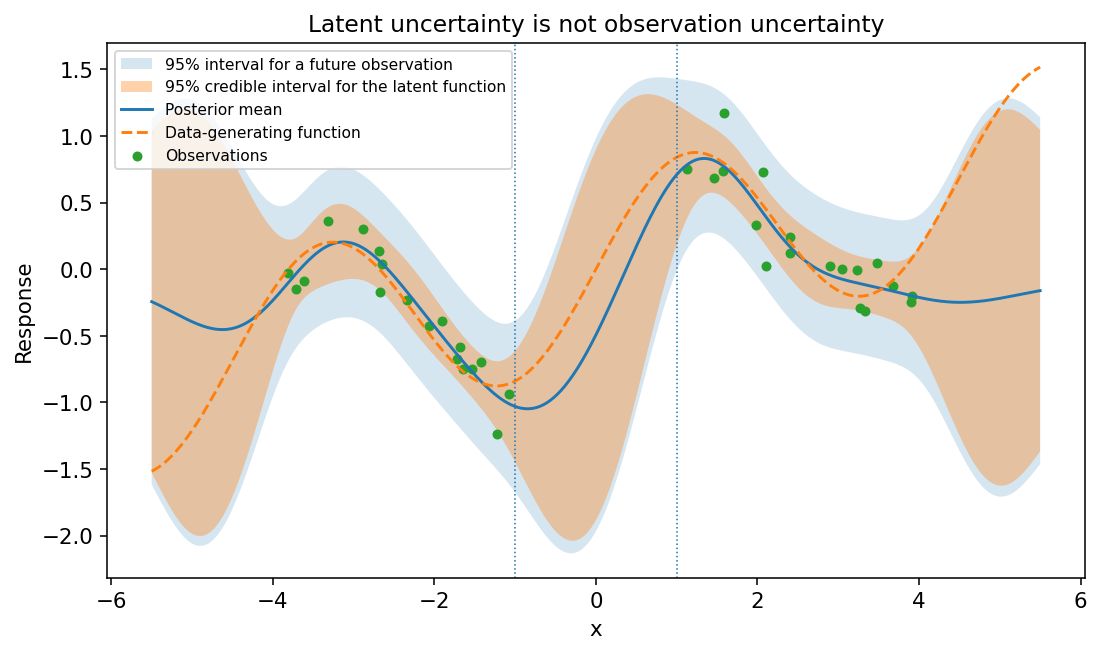

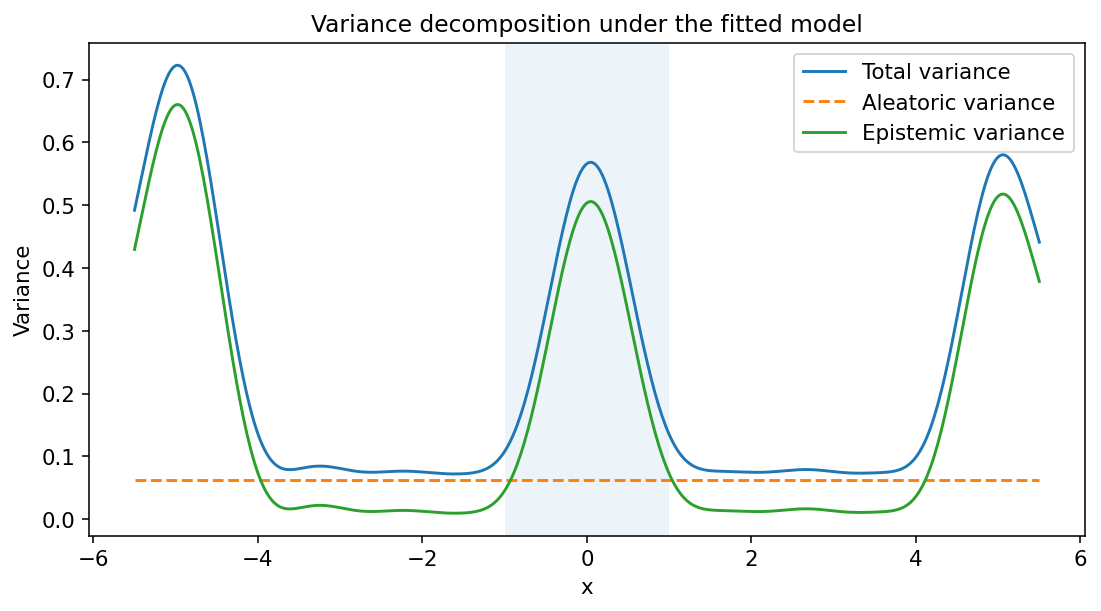

In [8]:
def regression_prediction(Phi, mean, covariance, sigma=NOISE_STD):
    """Posterior mean, latent variance, and future-observation variance."""
    prediction = Phi @ mean
    latent_variance = np.sum((Phi @ covariance) * Phi, axis=1)
    if np.min(latent_variance) < -1e-9:
        raise ArithmeticError("A posterior variance is unexpectedly negative.")
    latent_variance = np.maximum(latent_variance, 0.0)  # roundoff only
    return prediction, latent_variance, latent_variance + sigma**2


reg_mean, reg_epistemic, reg_total = regression_prediction(
    Phi_grid, weight_mean, weight_covariance)
reg_aleatoric = np.full_like(reg_epistemic, NOISE_STD**2)
z975 = norm.ppf(0.975)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.fill_between(x_reg_grid, reg_mean - z975 * np.sqrt(reg_total),
                reg_mean + z975 * np.sqrt(reg_total), alpha=0.18,
                label="95% interval for a future observation")
ax.fill_between(x_reg_grid, reg_mean - z975 * np.sqrt(reg_epistemic),
                reg_mean + z975 * np.sqrt(reg_epistemic), alpha=0.35,
                label="95% credible interval for the latent function")
ax.plot(x_reg_grid, reg_mean, label="Posterior mean")
ax.plot(x_reg_grid, true_function(x_reg_grid), "--", label="Data-generating function")
ax.scatter(x_reg, y_reg, s=17, label="Observations")
ax.axvline(-1, linestyle=":", linewidth=0.8)
ax.axvline(1, linestyle=":", linewidth=0.8)
ax.set(xlabel="x", ylabel="Response", title="Latent uncertainty is not observation uncertainty")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots()
ax.plot(x_reg_grid, reg_total, label="Total variance")
ax.plot(x_reg_grid, reg_aleatoric, "--", label="Aleatoric variance")
ax.plot(x_reg_grid, reg_epistemic, label="Epistemic variance")
ax.axvspan(-1, 1, alpha=0.08)
ax.set(xlabel="x", ylabel="Variance", title="Variance decomposition under the fitted model")
ax.legend()
fig.tight_layout()
plt.show()

### 2.4. Why the variance decomposition is general

Fix the test input $x$ and dataset $\mathcal D$. For any probabilistic model with finite second moments, let $\mu_\theta(x)=\mathbb E[Y\mid x,\theta]$ and $v_\theta(x)=\operatorname{Var}(Y\mid x,\theta)$. The expectation $\mathbb E_\theta$ and variance $\operatorname{Var}_\theta$ below are with respect to $p(\theta\mid\mathcal D)$. We assume the future outcome is conditionally independent of the training labels given $x$ and $\theta$.

Using iterated expectation and the identity $\mathbb E[Y^2\mid x,\theta]=v_\theta(x)+\mu_\theta(x)^2$,

$$
\begin{aligned}
\operatorname{Var}(Y\mid x,\mathcal D)
&=\mathbb E_\theta\!\left[v_\theta(x)+\mu_\theta(x)^2\right]
  -\left(\mathbb E_\theta[\mu_\theta(x)]\right)^2\\
&=\mathbb E_\theta[v_\theta(x)]
 +\left\{\mathbb E_\theta[\mu_\theta(x)^2]
         -\left(\mathbb E_\theta[\mu_\theta(x)]\right)^2\right\}\\
&=\mathbb E_\theta[v_\theta(x)]+\operatorname{Var}_\theta(\mu_\theta(x)).
\end{aligned}
$$

This is the law of total variance. The Bayesian regression model gives $\mu_w(x)=\phi(x)^\top w$ and $v_w(x)=\sigma^2$, recovering the two explicit terms above. Heteroscedastic models allow conditional observation variance to depend on $x$; in that case the aleatoric term need not be constant [1]. Uncertainty in the fixed hyperparameters and errors from an inadequate feature space are not included in our calculation.

In this experiment, the local basis leaves substantial function uncertainty in the gap. This behavior is model-dependent. Far outside all basis centres, the radial features vanish and only the intercept remains; uncertainty does not have to grow without bound merely because an input is far from the data.

### Exercise 2. Where should 20 new observations be taken? (10 minutes)

Complete `after_adding_points`. It should augment the original data, construct the new design matrix, refit the Gaussian posterior, and return the epistemic variance on the original plotting grid. Keep the basis, prior precision and observation noise fixed.

Compare two designs with the same budget: 20 inputs in the gap $[-0.9,0.9]$, or 20 inputs in the already observed interval $[-3,-2]$. The experiment reports mean epistemic variance inside the gap. Use the supplied checks to test that adding observations does not increase posterior function variance at any grid point, up to numerical error. For fixed hyperparameters this is a property of the Gaussian model, not just an empirical expectation.

In [9]:
def after_adding_points(x_new):
    """Augment the original regression data; return variance on Phi_grid."""
    x_new = np.asarray(x_new, dtype=float)
    new_rng = np.random.default_rng(201)
    y_new = true_function(x_new) + new_rng.normal(0, NOISE_STD, len(x_new))
    x_augmented = np.r_[x_reg, x_new]
    y_augmented = np.r_[y_reg, y_new]
    # TODO: form the design matrix at x_augmented.
    # TODO: obtain the new posterior covariance with fit_blr.
    # TODO: compute phi(x)^T S_new phi(x) at all rows of Phi_grid.
    return None


# Experiment and checks
gap_design = np.linspace(-0.9, 0.9, 20)
observed_design = np.linspace(-3.0, -2.0, 20)
gap_variance = after_adding_points(gap_design)
if gap_variance is None:
    print("Complete after_adding_points, then rerun this cell.")
else:
    observed_variance = after_adding_points(observed_design)
    gap_mask = np.abs(x_reg_grid) < 1
    for new_variance in (gap_variance, observed_variance):
        assert new_variance.shape == reg_epistemic.shape
        assert np.min(new_variance) >= -1e-10
        assert np.max(new_variance - reg_epistemic) < 1e-9
    rows = []
    fig, ax = plt.subplots()
    for name, variance in [("Original data", reg_epistemic),
                           ("20 labels in the gap", gap_variance),
                           ("20 labels in [-3, -2]", observed_variance)]:
        rows.append({"design": name, "mean gap epistemic variance": variance[gap_mask].mean(),
                     "aleatoric variance": NOISE_STD**2})
        ax.plot(x_reg_grid, variance, label=name)
    print(pd.DataFrame(rows).round(5).to_string(index=False))
    ax.axvspan(-1, 1, alpha=0.08)
    ax.set(xlabel="x", ylabel="Epistemic variance", title="A fixed observation budget, two locations")
    ax.legend(fontsize=9)
    fig.tight_layout()
    plt.show()

Complete after_adding_points, then rerun this cell.


### Questions

1. Which variance belongs in an interval for the latent function value, and which belongs in an interval for a future noisy observation?
2. With the basis, $\alpha$ and $\sigma$ fixed, why does the posterior covariance depend on the input locations but not on the measured responses?

### Bonus 2. Do the prediction intervals cover new observations?

For a desired probability $\rho\in(0,1)$, define the Gaussian prediction interval

$$
C_\rho(x)=\left[\mu(x)-G^{-1}\!\left(\frac{1+\rho}{2}\right)\sqrt{v_{\mathrm{total}}(x)},\ 
\mu(x)+G^{-1}\!\left(\frac{1+\rho}{2}\right)\sqrt{v_{\mathrm{total}}(x)}\right].
$$

Here $\mu(x)$ and $v_{\mathrm{total}}(x)$ are the fitted predictive mean and variance, and $G$ is again the standard normal cumulative distribution function. Marginal coverage concerns $P_{\mathrm{data}}\{Y\in C_\rho(X)\}$, a probability under the data-generating distribution, not under the fitted posterior predictive distribution. Its empirical estimate is the fraction of independent test observations inside their intervals.

Complete `empirical_coverage`. Evaluate nominal 95% intervals separately inside and outside the training gap. Then refit the same training responses while assuming half the true noise standard deviation, $\sigma_{\mathrm{fit}}=0.125$. The data-generating noise remains $0.25$; this is likelihood misspecification, not a less noisy experiment.

Report coverage and mean interval width together. Correct average coverage can conceal regional errors. Moreover, the fixed synthetic function is not a draw from the fitted finite-feature prior, so model-based 95% intervals have no automatic 95% frequentist coverage guarantee here.

In [10]:
def empirical_coverage(y, lower, upper):
    """Fraction of observations between their lower and upper endpoints."""
    y, lower, upper = map(np.asarray, (y, lower, upper))
    if y.shape != lower.shape or y.shape != upper.shape or y.size == 0:
        raise ValueError("Arrays must have the same nonempty shape.")
    # TODO: form the two-sided inclusion mask and return its mean.
    return None


# Experiment and checks
coverage_probe = empirical_coverage([0, 2], [-1, -1], [1, 1])
if coverage_probe is None:
    print("Complete empirical_coverage, then rerun this cell.")
else:
    np.testing.assert_allclose(coverage_probe, 0.5)
    coverage_rng = np.random.default_rng(222)
    x_coverage = coverage_rng.uniform(-4, 4, 4000)
    y_coverage = true_function(x_coverage) + coverage_rng.normal(0, NOISE_STD, len(x_coverage))
    Phi_coverage = rbf_features(x_coverage)
    rows = []
    for assumed_sigma in (NOISE_STD, NOISE_STD / 2):
        mean_w, covariance_w = fit_blr(Phi_train, y_reg, sigma=assumed_sigma)
        mu, _, variance = regression_prediction(Phi_coverage, mean_w, covariance_w,
                                                sigma=assumed_sigma)
        half_width = z975 * np.sqrt(variance)
        for name, mask in [("gap", np.abs(x_coverage) < 1),
                           ("observed input range", np.abs(x_coverage) >= 1)]:
            coverage = empirical_coverage(y_coverage[mask], (mu-half_width)[mask],
                                          (mu+half_width)[mask])
            rows.append({"assumed sigma": assumed_sigma, "region": name,
                         "coverage": coverage, "mean width": (2*half_width[mask]).mean()})
    print(pd.DataFrame(rows).round(4).to_string(index=False))

Complete empirical_coverage, then rerun this cell.


## 3. Classification with a neural-network ensemble

### 3.1. Two noisy semicircles and a conditional classifier

Return to binary classification, now with $x=(x_1,x_2)^\top\in\mathbb R^2$. We generate a two-moons distribution by sampling a label $Y\sim\operatorname{Bernoulli}(1/2)$ and an independent angle $U\sim\operatorname{Uniform}(0,\pi)$. Given the label and angle,

$$
X=\begin{cases}
(\cos U,\sin U)^\top+\eta,&Y=0,\\
(1-\cos U,\tfrac12-\sin U)^\top+\eta,&Y=1,
\end{cases}
\qquad \eta\sim\mathcal N(0,0.18^2I_2).
$$

The vector $\eta$ is independent of $U$ and $Y$, and $I_2$ is the two-dimensional identity matrix. Gaussian perturbations make the class-conditional distributions overlap. Even perfect knowledge of this joint distribution would not make every label deterministic given $X$.

Use 280 training observations, 800 separate calibration observations, and 1,600 separate test observations, all drawn independently from this distribution. Only the training observations are used to fit the classifiers. The calibration and test sets will be used in Section 4.

Each ensemble member has a Bernoulli likelihood with probability $p_\theta(x)=\sigma(z_\theta(x))$, where $\sigma(t)=1/(1+e^{-t})$ is the logistic sigmoid. Its neural network is

$$
\widetilde x_j=\frac{x_j-a_j}{s_j},\quad j=1,2,\qquad
h_1=\tanh(W_1\widetilde x+b_1),\quad
h_2=\tanh(W_2h_1+b_2),\quad
z_\theta(x)=v^\top h_2+b_3.
$$

Here $a_j$ and $s_j>0$ are the mean and standard deviation of input coordinate $j$ in that member's training sample. The hidden vectors $h_1,h_2$ have length 24; $W_1\in\mathbb R^{24\times2}$, $W_2\in\mathbb R^{24\times24}$, $b_1,b_2,v\in\mathbb R^{24}$, and $b_3\in\mathbb R$. The hyperbolic tangent is applied elementwise. The symbol $\theta$ collects the trainable weights and biases; input standardization is fitted on training data only.

For a training sample of size $N=280$, each member minimizes regularized binary negative log-likelihood:

$$
\mathcal L(\theta)
=-\frac1N\sum_{i=1}^{N}\left[y_i\log p_\theta(x_i)+(1-y_i)\log(1-p_\theta(x_i))\right]
+\frac{\lambda}{2N}\left(\|W_1\|_F^2+\|W_2\|_F^2+\|v\|_2^2\right),\qquad \lambda=0.01.
$$

The squared Frobenius norm is the sum of squared matrix entries; biases are not penalized. This is the objective convention used by `MLPClassifier` with the specified `alpha`. The optimizer is L-BFGS. Eight members use independent initializations and bootstrap samples: each sample draws $N$ training indices with replacement. This is a practical ensemble construction, not exact Bayesian inference. It is related to, but not a reproduction of, the training procedure in [4].

In [11]:
def sample_moons(n, seed, noise=0.18):
    """Independent samples from the two-semicircle distribution in the text."""
    rng = np.random.default_rng(seed)
    labels = rng.integers(0, 2, size=n)
    angle = rng.uniform(0, np.pi, size=n)
    features = np.column_stack([
        np.where(labels == 0, np.cos(angle), 1 - np.cos(angle)),
        np.where(labels == 0, np.sin(angle), 0.5 - np.sin(angle)),
    ])
    features += rng.normal(0, noise, size=features.shape)
    return features, labels


X_train, y_train = sample_moons(280, seed=7)
X_cal, y_cal = sample_moons(800, seed=17)
X_test, y_test = sample_moons(1600, seed=27)

N_MEMBERS = 8
ensemble = []
with threadpool_limits(limits=1):
    for member in range(N_MEMBERS):
        bootstrap_rng = np.random.default_rng(100 + member)
        indices = bootstrap_rng.integers(0, len(X_train), size=len(X_train))
        estimator = make_pipeline(
            StandardScaler(),
            MLPClassifier(hidden_layer_sizes=(24, 24), activation="tanh", solver="lbfgs",
                          alpha=0.01, max_iter=1800, max_fun=50000, random_state=member),
        )
        estimator.fit(X_train[indices], y_train[indices])
        ensemble.append(estimator)


def member_predictions(X):
    """Array of P(Y=1|x), shape (number of members, number of inputs)."""
    with threadpool_limits(limits=1):
        return np.stack([model.predict_proba(X)[:, 1] for model in ensemble])


print(f"Fitted {len(ensemble)} classifiers using only {len(X_train)} training examples.")

Fitted 8 classifiers using only 280 training examples.


### 3.2. Predictive distribution and entropy decomposition

Once the $M=8$ models are fitted, define a random member index $J$ uniform on $\{1,\ldots,M\}$. The resulting predictive distribution is a mixture of their Bernoulli predictions:

$$
\bar p_M(x)=\frac1M\sum_{m=1}^{M}p_{\theta_m}(x),\qquad
Y\mid x,\mathcal D\sim\operatorname{Bernoulli}(\bar p_M(x)).
$$

Equivalently, we have replaced the Bayesian posterior by the empirical distribution $q_M(\theta)=M^{-1}\sum_{m=1}^{M}\delta_{\theta_m}(\theta)$, where $\delta_{\theta_m}$ is a point mass at the fitted parameters of member $m$. The standardization statistics are fixed for each member and included in its prediction rule.

The same algebra as in Section 1 gives

$$
H_{\mathrm{pred}}(x)=h(\bar p_M(x)),\qquad
H_{\mathrm{within}}(x)=\frac1M\sum_{m=1}^{M}h(p_{\theta_m}(x)),\qquad
I_M(x)=H_{\mathrm{pred}}(x)-H_{\mathrm{within}}(x).
$$

The difference $I_M(x)$ is exactly $I(Y;J\mid x,\mathcal D)$ under this constructed mixture. It measures disagreement among the fitted members. Because these members are not posterior samples, it should not be presented as an exact estimate of Bayesian epistemic uncertainty. Likewise, expected member entropy is a within-model uncertainty score, not an identified ground-truth noise level.

For $K$ classes the same identity uses $H(p)=-\sum_{k=1}^{K}p_k\log p_k$, where $p=(p_1,\ldots,p_K)$ is a vector of class probabilities summing to 1. Average the probability vectors before taking predictive entropy. Averaging hard labels or logits gives a different object.

The plots below use the same range, $0$ to $\log2$, for all three entropy quantities. High predictive entropy may reflect ambiguous predictions within every member, disagreement between members, or both. Agreement outside the well-sampled region is not evidence that extrapolation is reliable; all members can share the same error [7].

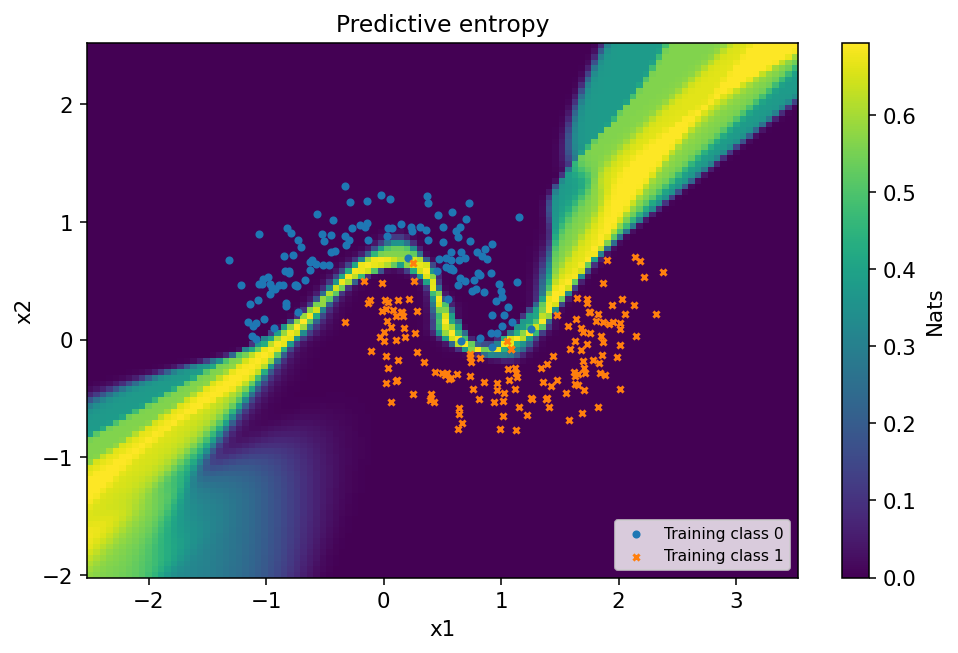

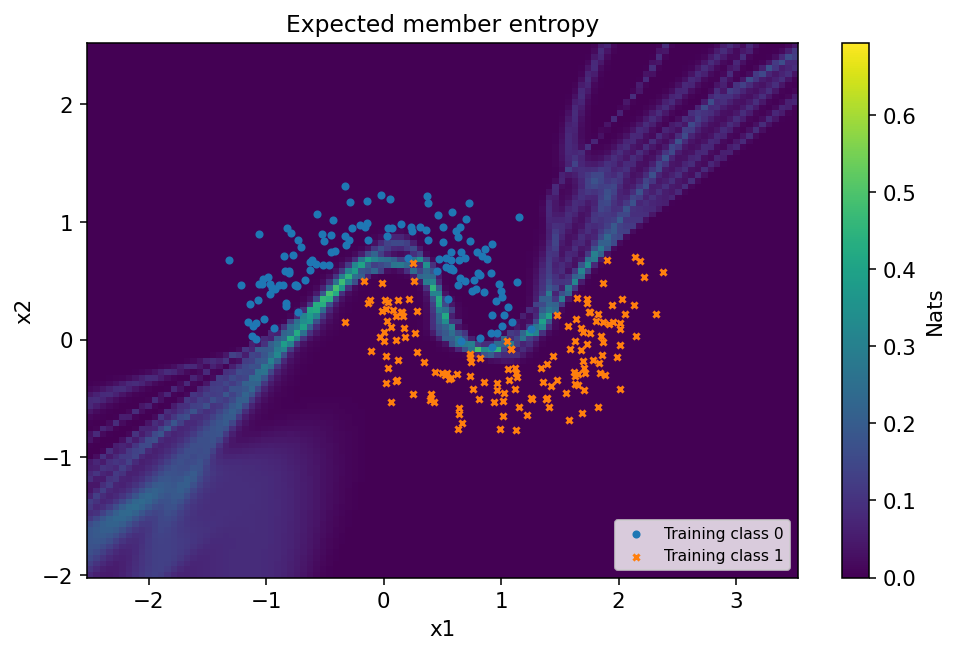

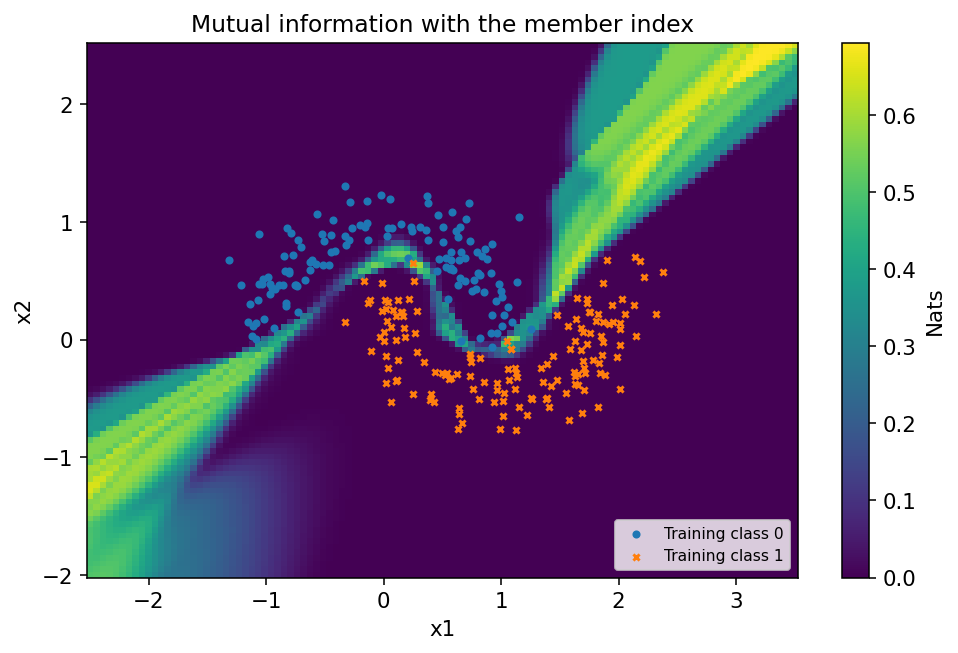

In [12]:
gx, gy = np.meshgrid(np.linspace(-2.5, 3.5, 110), np.linspace(-2, 2.5, 95))
classification_grid = np.column_stack([gx.ravel(), gy.ravel()])
P_grid = member_predictions(classification_grid)
mean_probability_grid = P_grid.mean(axis=0)
total_entropy_grid = binary_entropy(mean_probability_grid)
within_entropy_grid = binary_entropy(P_grid).mean(axis=0)
information_grid = total_entropy_grid - within_entropy_grid
assert information_grid.min() > -1e-12

for values, title in [(total_entropy_grid, "Predictive entropy"),
                       (within_entropy_grid, "Expected member entropy"),
                       (information_grid, "Mutual information with the member index")]:
    fig, ax = plt.subplots(figsize=(7.2, 4.8))
    image = ax.pcolormesh(gx, gy, values.reshape(gx.shape), shading="auto", vmin=0, vmax=np.log(2))
    for label, marker in [(0, "o"), (1, "x")]:
        mask = y_train == label
        ax.scatter(X_train[mask, 0], X_train[mask, 1], s=10, marker=marker,
                   label=f"Training class {label}")
    ax.set(xlabel="x1", ylabel="x2", title=title)
    ax.legend(fontsize=8, loc="lower right")
    fig.colorbar(image, ax=ax, label="Nats")
    fig.tight_layout()
    plt.show()

### Exercise 3. Does a larger ensemble change the conclusion? (10 minutes)

Complete `ensemble_decomposition` for an array of positive-class probabilities of shape $(M,n)$: rows are members and columns are inputs. Return three arrays of length $n$: predictive entropy, expected member entropy and their difference. Average along the member axis.

The supplied experiment examines three fixed inputs with ensemble sizes $M=1,2,4,8$, reusing trained members rather than fitting new models. Check the identities for a one-member ensemble and for an ensemble in which every member is duplicated. Compare the changes at an observed region, an intermediate region and a distant input. Prefixes of a finite ensemble are different empirical distributions, so their mutual information need not increase monotonically with size.

In [13]:
def ensemble_decomposition(member_probabilities):
    """Entropy terms for a binary ensemble, input shape (M, n)."""
    probabilities = np.asarray(member_probabilities, dtype=float)
    if probabilities.ndim != 2 or min(probabilities.shape) == 0:
        raise ValueError("Expected a nonempty array with shape (M, n).")
    # TODO: average probabilities over members, then take entropy.
    # TODO: average the individual entropies over members.
    # TODO: return total entropy, within entropy, and their difference.
    return None


# Experiment and checks
probe_points = np.array([[-0.8, 0.6], [0.5, 0.25], [3.0, 2.0]])
probe_names = ["Near training observations", "Between the moons", "Distant input"]
P_probe = member_predictions(probe_points)
probe_terms = ensemble_decomposition(P_probe)
if probe_terms is None:
    print("Complete ensemble_decomposition, then rerun this cell.")
else:
    H_probe, A_probe, I_probe = probe_terms
    np.testing.assert_allclose(H_probe, A_probe + I_probe)
    assert I_probe.min() >= -1e-12
    np.testing.assert_allclose(ensemble_decomposition(P_probe[:1])[2], 0, atol=1e-12)
    duplicated = np.repeat(P_probe, 2, axis=0)
    for original, repeated in zip(probe_terms, ensemble_decomposition(duplicated)):
        np.testing.assert_allclose(original, repeated, atol=1e-12)
    print(pd.DataFrame({"input": probe_names, "mean P(Y=1)": P_probe.mean(axis=0),
                        "total H": H_probe, "within H": A_probe, "MI": I_probe})
          .round(4).to_string(index=False))
    sizes = np.array([1, 2, 4, 8])
    information_by_size = np.array([ensemble_decomposition(P_probe[:m])[2] for m in sizes])
    fig, ax = plt.subplots()
    for j, name in enumerate(probe_names):
        ax.plot(sizes, information_by_size[:, j], marker="o", label=name)
    ax.set(xlabel="Number of fitted members used", ylabel="Mutual information (nats)",
           xticks=sizes, title="Ensemble-size sensitivity at fixed inputs")
    ax.legend(fontsize=9)
    fig.tight_layout()
    plt.show()

Complete ensemble_decomposition, then rerun this cell.


### Questions

1. Can an input have almost zero ensemble mutual information while the prediction is confidently wrong? Explain what the score does and does not measure.
2. Why does duplicating every ensemble member leave all three entropy quantities unchanged, whereas adding a newly trained member can change them?

### Bonus 3. Uncertainty-based abstention

Use a separate exploration set, not the final calibration or test set. Sort its inputs by increasing uncertainty, retain a specified fraction $c\in(0,1]$, and compute the classification error among retained inputs. This is a risk–coverage curve: coverage is the fraction on which a prediction is made, and risk is the error rate on that fraction.

For $n$ exploration examples, let $R_c$ be the indices of the $\lceil cn\rceil$ lowest-uncertainty predictions, where $\lceil\cdot\rceil$ rounds upward. With $\widehat y_i=\mathbf1\{\bar p_M(x_i)\geq1/2\}$,

$$
\widehat{\operatorname{risk}}(c)=\frac{1}{|R_c|}\sum_{i\in R_c}\mathbf1\{\widehat y_i\neq y_i\}.
$$

The indicator $\mathbf1\{E\}$ is 1 when event $E$ occurs and 0 otherwise. Complete `selective_risk`; compare predictive entropy, mutual information, and the expected risk of retaining a uniformly random subset, which equals the full-set error. Decreasing coverage does not mathematically guarantee decreasing empirical error for an arbitrary score. This experiment tests whether a score is useful for abstention on this distribution; it is not a calibration test.

In [14]:
def selective_risk(y_true, predictions, uncertainty, coverages):
    """Error after retaining the least-uncertain fraction of examples."""
    y_true, predictions = np.asarray(y_true), np.asarray(predictions)
    coverages = np.asarray(coverages, dtype=float)
    if np.any((coverages <= 0) | (coverages > 1)):
        raise ValueError("Coverages must lie in (0, 1].")
    # TODO: sort input indices by increasing uncertainty.
    # TODO: for each coverage, retain ceil(c*n) indices and compute error.
    return None


# Experiment and checks
if ensemble_decomposition(P_probe) is None:
    print("Complete Exercise 3 before Bonus 3.")
elif selective_risk([0, 1], [0, 0], [0.1, 0.2], [0.5, 1.0]) is None:
    print("Complete selective_risk, then rerun this cell.")
else:
    np.testing.assert_allclose(selective_risk([0, 1], [0, 0], [0.1, 0.2], [0.5, 1]), [0, 0.5])
    X_explore, y_explore = sample_moons(600, seed=37)
    P_explore = member_predictions(X_explore)
    H_explore, _, I_explore = ensemble_decomposition(P_explore)
    predicted_explore = (P_explore.mean(axis=0) >= 0.5).astype(int)
    coverages = np.linspace(0.2, 1.0, 9)
    fig, ax = plt.subplots()
    for name, scores in [("Predictive entropy", H_explore), ("Mutual information", I_explore)]:
        risks = selective_risk(y_explore, predicted_explore, scores, coverages)
        ax.plot(coverages, risks, marker="o", label=name)
    ax.axhline(np.mean(predicted_explore != y_explore), linestyle="--", label="Expected random-subset risk")
    ax.set(xlabel="Retained fraction (coverage)", ylabel="Classification error (risk)",
           title="Abstention evaluated on a separate exploration set")
    ax.legend(fontsize=9)
    fig.tight_layout()
    plt.show()

Complete Exercise 3 before Bonus 3.


## 4. Calibration of the same classifier

### 4.1. A controlled probability distortion

Keep the fitted ensemble from Section 3. Its positive-class probability is $\bar p_M(x)$. Define its aggregate logit and deliberately sharpen it:

$$
z_{\mathrm{base}}(x)=\log\frac{\bar p_M(x)}{1-\bar p_M(x)},\qquad
z(x)=a\,z_{\mathrm{base}}(x),\quad a=2.5,\qquad
\widehat p(x)=\sigma(z(x)).
$$

The scalar $a$ is a known distortion applied after training, not a learned model parameter. The logit maps probabilities in $(0,1)$ to the real line; numerical clipping is used only to avoid infinite logits at floating-point endpoints. This is the logit of the ensemble-averaged probability, not the average of member logits.

Because $a>0$, the predicted class at threshold $1/2$ is unchanged. The probability becomes more extreme unless it equals $1/2$. This supplies a reproducible miscalibration experiment. The original ensemble need not be calibrated, so we will not assume that undoing the factor $a$ is the optimal correction.

In [15]:
def probability_to_logit(p, eps=1e-12):
    """Finite binary log-odds; clipping is only for numerical endpoints."""
    p = np.clip(np.asarray(p, dtype=float), eps, 1 - eps)
    return np.log(p) - np.log1p(-p)


SHARPENING = 2.5
p_cal_base = member_predictions(X_cal).mean(axis=0)
z_cal = SHARPENING * probability_to_logit(p_cal_base)
example_probabilities = np.array([0.05, 0.20, 0.50, 0.80, 0.95])
print(pd.DataFrame({"original probability": example_probabilities,
                    "sharpened probability": expit(SHARPENING * probability_to_logit(example_probabilities))})
      .round(4).to_string(index=False))

 original probability  sharpened probability
                 0.05                 0.0006
                 0.20                 0.0303
                 0.50                 0.5000
                 0.80                 0.9697
                 0.95                 0.9994


### 4.2. What calibration asks

Treat a trained predictor $\widehat p$ as fixed, and let $(X,Y)$ be a new observation from the distribution on which it is evaluated. Binary positive-class calibration means

$$
\mathbb E[Y\mid\widehat p(X)]=\widehat p(X)\quad\text{almost surely}.
$$

Equivalently, the conditional frequency of label 1 among predictions at probability level $q$ is $q$, for probability levels supported by the prediction distribution. With continuous predictions, conditioning is understood through a regular conditional expectation; it does not require the event $\widehat p(X)=q$ to have positive probability. In a finite dataset, we approximate this statement by pooling nearby probabilities.

This is not the same as accuracy, sharpness, or small uncertainty. A constant predictor equal to the population class frequency is calibrated but cannot distinguish inputs. A confident classifier may have high accuracy yet overstate the probability of its correct predictions. For multiclass problems, classwise calibration and calibration of the maximum predicted probability are different properties. Here every reliability calculation concerns the probability of the positive class, including probabilities below $1/2$ [5,6].

### 4.3. Reliability diagrams and scores

Let $(p_i,y_i)_{i=1}^{n}$ be predicted probabilities and labels on an evaluation set. Divide $[0,1]$ into $B$ equal-width bins. Bin $b$ is $[(b-1)/B,b/B)$ for $b<B$; the last bin includes 1. Define its index set $I_b=\{i:p_i\text{ is in bin }b\}$ and count $n_b=|I_b|$. In each nonempty bin,

$$
\overline p_b=\frac1{n_b}\sum_{i\in I_b}p_i,\qquad
\overline y_b=\frac1{n_b}\sum_{i\in I_b}y_i.
$$

A reliability diagram plots $(\overline p_b,\overline y_b)$. Sparse bins have noisy frequency estimates, so their counts matter. The binned positive-class expected calibration error is

$$
\widehat{\operatorname{ECE}}_B
=\sum_{b:n_b>0}\frac{n_b}{n}|\overline y_b-\overline p_b|.
$$

Empty bins contribute zero. This particular estimator concerns positive-class calibration; it is not the frequently used top-confidence ECE. It depends on bin edges and sample size, and it is not a proper scoring rule or an exact population calibration error. A zero value can conceal errors that cancel inside a bin.

Two complementary prediction losses are binary negative log-likelihood and the binary Brier score:

$$
\operatorname{NLL}=-\frac1n\sum_{i=1}^{n}\left[y_i\log p_i+(1-y_i)\log(1-p_i)\right],\qquad
\operatorname{Brier}=\frac1n\sum_{i=1}^{n}(p_i-y_i)^2.
$$

Lower is better for both. This Brier convention uses a single positive-class probability; summing squared errors over both binary classes would multiply the value by 2. At a fixed input with true positive-class probability $\eta$, the expected Brier loss is $(p-\eta)^2+\eta(1-\eta)$. The expected NLL is $h(\eta)+\operatorname{KL}(\operatorname{Bernoulli}(\eta)\Vert\operatorname{Bernoulli}(p))$. Both are uniquely minimized by $p=\eta$, which is the meaning of strict propriety. Neither measures calibration alone [6].

In [16]:
def binary_nll_from_logits(logits, labels):
    """Mean Bernoulli NLL, evaluated without taking logs of rounded probabilities."""
    logits, labels = np.asarray(logits, dtype=float), np.asarray(labels, dtype=float)
    if logits.shape != labels.shape or logits.size == 0 or np.any(~np.isfinite(logits)):
        raise ValueError("Use matching nonempty arrays and finite logits.")
    if np.any((labels != 0) & (labels != 1)):
        raise ValueError("Labels must be 0 or 1.")
    return np.mean(np.logaddexp(0.0, logits) - labels * logits)


def reliability_table(labels, probabilities, n_bins=10):
    """Positive-class reliability; left-closed bins, final bin includes 1."""
    labels, probabilities = np.asarray(labels), np.asarray(probabilities, dtype=float)
    if labels.ndim != 1 or probabilities.shape != labels.shape or labels.size == 0:
        raise ValueError("Use matching, nonempty, one-dimensional arrays.")
    if not isinstance(n_bins, (int, np.integer)) or n_bins < 1:
        raise ValueError("n_bins must be a positive integer.")
    if np.any((labels != 0) & (labels != 1)):
        raise ValueError("Labels must be binary.")
    binary_entropy(probabilities)  # checks range and finiteness
    edges = np.linspace(0, 1, n_bins + 1)
    assignments = np.searchsorted(edges[1:-1], probabilities, side="right")
    rows = []
    for bin_index in range(n_bins):
        mask = assignments == bin_index
        if mask.any():
            rows.append({"bin": bin_index + 1, "count": int(mask.sum()),
                         "mean_probability": probabilities[mask].mean(),
                         "positive_frequency": labels[mask].mean()})
    return pd.DataFrame(rows)


def prediction_metrics(name, logits, labels):
    probabilities = expit(logits)
    return {"predictor": name, "accuracy": np.mean((logits >= 0) == labels),
            "NLL": binary_nll_from_logits(logits, labels),
            "Brier": np.mean((probabilities - labels)**2)}


endpoint_check = reliability_table([0, 1, 1], [0, 0.5, 1], n_bins=2)
assert endpoint_check["count"].tolist() == [1, 2]
np.testing.assert_allclose(binary_nll_from_logits(np.zeros(2), [0, 1]), np.log(2))

### 4.4. Temperature scaling and data separation

Temperature scaling uses a single positive parameter $T$ to transform the distorted logits [5]:

$$
\widehat p_T(x)=\sigma\!\left(\frac{z(x)}{T}\right),\qquad T>0.
$$

A temperature above 1 moves probabilities toward $1/2$; a temperature below 1 makes them more extreme. For any positive finite $T$, the sign of $z$ and the predicted class are unchanged. It is therefore possible to improve probability estimates without changing accuracy.

Use only the calibration set $\mathcal D_{\mathrm{cal}}=\{(x_i^{\mathrm{cal}},y_i^{\mathrm{cal}})\}_{i=1}^{n_{\mathrm{cal}}}$, with $n_{\mathrm{cal}}=800$, to choose $T$. With $z_i=z(x_i^{\mathrm{cal}})$,

$$
\widehat T=\underset{T>0}{\operatorname{argmin}}\ \frac1{n_{\mathrm{cal}}}
\sum_{i=1}^{n_{\mathrm{cal}}}\left[
\log\!\left(1+\exp\!\left(\frac{z_i}{T}\right)\right)
-y_i^{\mathrm{cal}}\frac{z_i}{T}\right].
$$

The expression is the same binary NLL as above, written in terms of logits. `logaddexp(0, u)` evaluates $\log(1+e^u)$ stably. Optimize $\tau=\log T$ so that $T=e^\tau$ is positive. The code restricts $T$ to $[0.05,20]$ for numerical convenience; the fitted value should be checked against these bounds. A boundary optimum would be a constrained fit, not proof of an unconstrained optimum.

Training labels fit the network weights, calibration labels fit $T$, and the final test labels evaluate the frozen result. Do not select $T$, bin counts, or model hyperparameters by optimizing the final test metrics. Fitting NLL on the calibration set does not guarantee improvement of test NLL, Brier score or a particular binned ECE. A scalar temperature cannot repair an arbitrary input-dependent probability error, nor does calibration on one distribution establish calibration after a distribution change [7].

### Exercise 4. Fit and evaluate a temperature (10 minutes)

Complete the objective inside `fit_temperature`: transform calibration logits by the positive temperature and evaluate their NLL. Optimize over the supplied log-temperature interval and return $T$, not $\log T$.

The remaining code uses the fitted temperature once on the untouched test set. Compare accuracy, NLL and Brier score before and after scaling, and inspect the reliability diagram with 10 bins. Check that the fitted value is not at a bound, that calibration NLL is no larger than at $T=1$ within numerical tolerance, and that test class decisions are exactly unchanged.

In [17]:
def fit_temperature(calibration_logits, calibration_labels):
    """Fit one positive temperature using calibration labels only."""
    def objective(log_temperature):
        # TODO: convert log_temperature to T, scale the logits, evaluate NLL.
        return None

    # Remove this guard after filling the objective, or leave it for checking.
    if objective(0.0) is None:
        return None
    result = minimize_scalar(objective, bounds=(np.log(0.05), np.log(20.0)), method="bounded")
    if not result.success:
        raise RuntimeError(result.message)
    return float(np.exp(result.x))


# Experiment and checks
T_fit = fit_temperature(z_cal, y_cal)
if T_fit is None:
    print("Complete fit_temperature, then rerun this cell.")
else:
    assert 0.05 < T_fit < 20
    assert binary_nll_from_logits(z_cal / T_fit, y_cal) <= binary_nll_from_logits(z_cal, y_cal) + 1e-7
    if min(T_fit / 0.05, 20 / T_fit) < 1.01:
        print("The fitted temperature is close to an optimization bound.")
    p_test_base = member_predictions(X_test).mean(axis=0)
    z_test = SHARPENING * probability_to_logit(p_test_base)
    p_test_before, p_test_after = expit(z_test), expit(z_test / T_fit)
    assert np.array_equal(p_test_before >= 0.5, p_test_after >= 0.5)
    print(f"Fitted temperature: {T_fit:.4f}")
    comparison = pd.DataFrame([
        prediction_metrics("Before scaling", z_test, y_test),
        prediction_metrics("After scaling", z_test / T_fit, y_test),
    ])
    print(comparison.round(4).to_string(index=False))
    fig, ax = plt.subplots()
    ax.plot([0, 1], [0, 1], "--", label="Calibration identity")
    for name, probabilities in [("Before scaling", p_test_before), ("After scaling", p_test_after)]:
        table = reliability_table(y_test, probabilities, n_bins=10)
        ax.plot(table["mean_probability"], table["positive_frequency"], marker="o", label=name)
    ax.set(xlabel="Mean predicted P(Y=1) in bin", ylabel="Observed positive-label frequency",
           xlim=(0, 1), ylim=(0, 1), title="Test reliability after fitting T on calibration data")
    ax.legend(fontsize=9)
    fig.tight_layout()
    plt.show()
    print("Bin counts after scaling:", reliability_table(y_test, p_test_after)["count"].tolist())

Complete fit_temperature, then rerun this cell.


### Questions

1. Why can the constant predictor $\widehat p(x)=1/2$ be calibrated on this population while being uninformative about individual labels?
2. Why can positive temperature scaling change NLL and Brier score but not accuracy at threshold $1/2$?

### Bonus 4. Binning and a change in label noise

Complete `binary_ece` using the bin counts and means returned by `reliability_table`. Check probabilities at 0 and 1 and bins with no observations. Report ECE before and after scaling for $B=5,10,20,40$; these are predetermined diagnostics, not candidates from which to select the most flattering result.

Next draw a fresh dataset and independently flip each label with probability $r=0.15$, leaving inputs unchanged. If the original conditional positive-class probability is $\eta(x)$, the changed population has

$$
P(Y'=1\mid X=x)=r+(1-2r)\eta(x),\qquad r=0.15.
$$

Here $Y'$ is the flipped label. Keep all model parameters and the original temperature fixed. Compare probability losses and reliability on the changed population. This is a change in the conditional label distribution, not merely a change in input frequency. A temperature fitted to the original labels need not remain appropriate.

In [18]:
def binary_ece(labels, probabilities, n_bins=10):
    """Binned positive-class ECE; empty bins are omitted by reliability_table."""
    table = reliability_table(labels, probabilities, n_bins)
    # TODO: weight the absolute frequency/probability gaps by bin count / n.
    return None


# Experiment and checks
if T_fit is None:
    print("Complete Exercise 4 before Bonus 4.")
elif binary_ece([0, 1], [0.0, 1.0]) is None:
    print("Complete binary_ece, then rerun this cell.")
else:
    np.testing.assert_allclose(binary_ece([0, 1], [0.0, 1.0], n_bins=10), 0)
    np.testing.assert_allclose(binary_ece([0, 1], [0.5, 0.5], n_bins=10), 0)
    np.testing.assert_allclose(binary_ece([1, 0], [0.0, 1.0], n_bins=10), 1)
    bin_rows = [{"bins": b, "ECE before": binary_ece(y_test, p_test_before, b),
                 "ECE after": binary_ece(y_test, p_test_after, b)} for b in (5, 10, 20, 40)]
    print(pd.DataFrame(bin_rows).round(4).to_string(index=False))
    X_shift, y_shift_original = sample_moons(1600, seed=47)
    flips = np.random.default_rng(48).random(len(y_shift_original)) < 0.15
    y_shift = np.logical_xor(y_shift_original, flips).astype(int)
    z_shift = SHARPENING * probability_to_logit(member_predictions(X_shift).mean(axis=0))
    shift_metrics = pd.DataFrame([
        prediction_metrics("Shift: before scaling", z_shift, y_shift),
        prediction_metrics("Shift: original T", z_shift / T_fit, y_shift),
    ])
    print(shift_metrics.round(4).to_string(index=False))
    print("Shift ECE, original T (10 bins):", round(binary_ece(y_shift, expit(z_shift/T_fit)), 4))
    fig, ax = plt.subplots()
    ax.plot([0, 1], [0, 1], "--", label="Calibration identity")
    for name, labels, probabilities in [("Original population", y_test, p_test_after),
                                         ("Changed label noise", y_shift, expit(z_shift / T_fit))]:
        table = reliability_table(labels, probabilities)
        ax.plot(table["mean_probability"], table["positive_frequency"], marker="o", label=name)
    ax.set(xlabel="Mean predicted P(Y=1) in bin", ylabel="Observed positive-label frequency",
           xlim=(0, 1), ylim=(0, 1), title="A fixed temperature on two label distributions")
    ax.legend(fontsize=9)
    fig.tight_layout()
    plt.show()

Complete Exercise 4 before Bonus 4.


## 5. Conclusions

A probability model specifies the random quantity being predicted and which sources of uncertainty it represents. In Gaussian regression, posterior variance of the latent function and variance of a future noisy observation are different. In classification, entropy of the average prediction and average entropy of individual predictions are different.

The variance and entropy decompositions are exact identities under their respective joint distributions. Interpreting their components as real-world aleatoric or epistemic uncertainty requires adequate modeling assumptions. In particular, ensemble agreement is not a guarantee of correctness, and a fixed feature space omits uncertainty about alternative representations.

Calibration is a separate statistical property linking reported predictions to observed outcomes on a specified population. It is assessed with held-out data and a clearly stated prediction object. Reliability diagrams, interval coverage and proper scoring rules answer related but nonidentical questions. Neither a low uncertainty score nor a single low ECE value is a general certificate of reliable prediction.

## References

[1] A. Kendall and Y. Gal. What Uncertainties Do We Need in Bayesian Deep Learning for Computer Vision? NeurIPS, 2017. [Paper](https://proceedings.neurips.cc/paper_files/paper/2017/hash/2650d6089a6d640c5e85b2b88265dc2b-Abstract.html).

[2] N. Houlsby, F. Huszár, Z. Ghahramani and M. Lengyel. Bayesian Active Learning for Classification and Preference Learning. arXiv:1112.5745, 2011. [Paper](https://arxiv.org/abs/1112.5745).

[3] C. E. Rasmussen and C. K. I. Williams. Gaussian Processes for Machine Learning. MIT Press, 2006. Chapter 2, especially the weight-space view. [Chapter](https://gaussianprocess.org/gpml/chapters/RW2.pdf).

[4] B. Lakshminarayanan, A. Pritzel and C. Blundell. Simple and Scalable Predictive Uncertainty Estimation using Deep Ensembles. NeurIPS, 2017. [Paper](https://proceedings.neurips.cc/paper/2017/hash/9ef2ed4b7fd2c810847ffa5fa85bce38-Abstract.html).

[5] C. Guo, G. Pleiss, Y. Sun and K. Q. Weinberger. On Calibration of Modern Neural Networks. ICML, PMLR 70:1321–1330, 2017. [Paper](https://proceedings.mlr.press/v70/guo17a.html).

[6] T. Gneiting and A. E. Raftery. Strictly Proper Scoring Rules, Prediction, and Estimation. Journal of the American Statistical Association, 102(477):359–378, 2007. [Article](https://doi.org/10.1198/016214506000001437).

[7] Y. Ovadia et al. Can You Trust Your Model's Uncertainty? Evaluating Predictive Uncertainty Under Dataset Shift. NeurIPS, 2019. [Paper](https://papers.neurips.cc/paper_files/paper/2019/hash/8558cb408c1d76621371888657d2eb1d-Abstract.html).